# **Hotel Booking : Analyse SQL**

##### **Objectif** : répondre en SQL à 6 questions métier sur les **réservations**, les **annulations** et les **segments de clientèle**, avec une interprétation utile à la direction pour chaque résultat.
##### **Données** : fichier nettoyé `reservations_nettoyees.csv` (86 637 réservations, après suppression des doublons, des clients fantômes et des séjours sans nuit).
##### **Moteur** : **SQLite** (inclus dans Python, aucune installation). Le fichier CSV est chargé dans une table `reservations`, puis interrogé en SQL.

| Requête | Question | Techniques SQL |
|---|---|---|
| 1 | Vue d'ensemble par hôtel | `GROUP BY`, `COUNT`, `SUM`, `AVG`, `CASE WHEN` |
| 2 | Segments : volume, risque, CA | Agrégats, **sous-requêtes**, `HAVING` |
| 3 | Évolution mensuelle par hôtel | **CTE** + fenêtrage **`LAG()`** |
| 4 | Top 10 des agents | **CTE**, fenêtrage **`RANK()`** et **`SUM() OVER`**, sous-requête |
| 5 | Délai de réservation | **CTE** + `CASE WHEN` (tranches) |
| 6 | Profils les plus exposés | `GROUP BY` sur 2 colonnes, `HAVING`, `LIMIT` |

##### ***Rappel*** : `total_revenue` = durée du séjour × prix moyen par nuit. C'est une **estimation** du CA : **CA réalisé** = réservations non annulées, **CA perdu** = réservations annulées (manque à gagner potentiel).

## **1. Création de la base de données**

##### On importe les bibliothèques, on charge le CSV nettoyé, puis on crée la base SQLite `hotel_booking.db` avec une table `reservations`.

In [3]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [4]:
# Chargement du fichier nettoyé (à placer dans le même dossier que ce notebook)
df = pd.read_csv("reservations_nettoyees.csv")
print("Dimensions :", df.shape)

# Sécurité : on recrée les colonnes calculées si elles sont absentes
if "duree_sejour" not in df.columns:
    df["duree_sejour"] = df["nuits_semaine"] + df["nuits_weekend"]
if "total_revenue" not in df.columns:
    df["total_revenue"] = df["duree_sejour"] * df["prix_moyen_nuit"]
if "num_mois" not in df.columns:
    mois = ["January", "February", "March", "April", "May", "June", "July",
            "August", "September", "October", "November", "December"]
    df["num_mois"] = df["mois_arrivee"].map({m: i + 1 for i, m in enumerate(mois)})

Dimensions : (86637, 48)


In [5]:
# Création de la base SQLite et de la table "reservations"
conn = sqlite3.connect("hotel_booking.db")
df.to_sql("reservations", conn, if_exists="replace", index=False)

# Fonction utilitaire : exécute une requête SQL et renvoie un DataFrame
def sql(requete):
    return pd.read_sql(requete, conn)

print("Table 'reservations' créée.")

Table 'reservations' créée.


##### **Structure de la table** : liste des colonnes et de leur type, lue directement dans la base.

In [6]:
sql("PRAGMA table_info(reservations);")[["name", "type"]]

,name,type
0,hotel,TEXT
1,est_annule,INTEGER
2,delai_reservation_jours,INTEGER
3,annee_arrivee,INTEGER
4,mois_arrivee,TEXT
5,semaine_arrivee,INTEGER
6,jour_arrivee,INTEGER
7,nuits_weekend,INTEGER
8,nuits_semaine,INTEGER
9,adultes,INTEGER


##### **Contrôle** : on vérifie que la base contient bien toutes les réservations du fichier nettoyé.

In [7]:
requete_verif = """
SELECT COUNT(*)                              AS nb_reservations,
       SUM(est_annule)                       AS nb_annulations,
       ROUND(100.0 * AVG(est_annule), 1)     AS taux_annulation_pct,
       ROUND(SUM(total_revenue) / 1e6, 2)    AS ca_potentiel_meur
FROM reservations;
"""
sql(requete_verif)

,nb_reservations,nb_annulations,taux_annulation_pct,ca_potentiel_meur
0,86637,23985,27.7,34.45


##### ✅ **Contrôle** : 86 637 réservations, 23 985 annulations, soit un taux de **27,7 %**, et environ **34,5 M€** de CA potentiel (réalisé + perdu). Les chiffres correspondent au fichier nettoyé utilisé en Python.

---
## **2. Requête 1 : Vue d'ensemble par hôtel**
##### **Question** : pour chaque hôtel, combien de réservations, quel taux d'annulation, quel CA réalisé et quel CA perdu ?
##### **Techniques** : `GROUP BY`, `COUNT`, `SUM`, `AVG`, et `CASE WHEN` pour séparer le CA réalisé du CA perdu.
##### ***Astuce*** : `est_annule` vaut 0 ou 1, donc `AVG(est_annule)` donne directement le taux d'annulation.

In [8]:
requete_q1 = """
SELECT hotel,
       COUNT(*)                                                             AS nb_reservations,
       SUM(est_annule)                                                      AS nb_annulations,
       ROUND(100.0 * AVG(est_annule), 1)                                    AS taux_annulation_pct,
       ROUND(SUM(CASE WHEN est_annule = 0 THEN total_revenue ELSE 0 END) / 1e6, 2) AS ca_realise_meur,
       ROUND(SUM(CASE WHEN est_annule = 1 THEN total_revenue ELSE 0 END) / 1e6, 2) AS ca_perdu_meur,
       ROUND(100.0 * SUM(CASE WHEN est_annule = 1 THEN total_revenue ELSE 0 END)
             / SUM(total_revenue), 1)                                       AS part_ca_perdu_pct
FROM reservations
GROUP BY hotel
ORDER BY nb_reservations DESC;
"""
q1 = sql(requete_q1)
q1

,hotel,nb_reservations,nb_annulations,taux_annulation_pct,ca_realise_meur,ca_perdu_meur,part_ca_perdu_pct
0,City Hotel,53042,16021,30.2,12.15,6.61,35.2
1,Resort Hotel,33595,7964,23.7,10.82,4.87,31.0


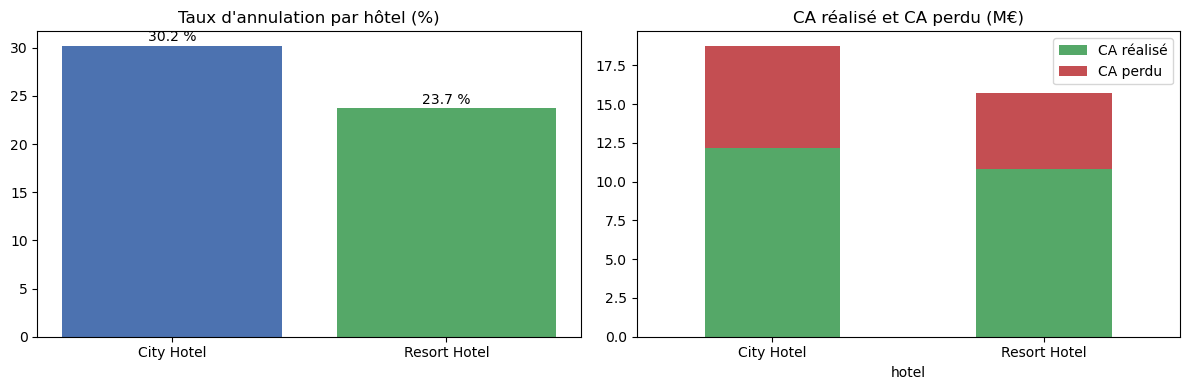

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(q1["hotel"], q1["taux_annulation_pct"], color=["#4C72B0", "#55A868"])
axes[0].set_title("Taux d'annulation par hôtel (%)")
for i, v in enumerate(q1["taux_annulation_pct"]):
    axes[0].text(i, v + 0.5, f"{v} %", ha="center")

q1.set_index("hotel")[["ca_realise_meur", "ca_perdu_meur"]].plot(
    kind="bar", stacked=True, ax=axes[1], color=["#55A868", "#C44E52"], rot=0)
axes[1].set_title("CA réalisé et CA perdu (M€)")
axes[1].legend(["CA réalisé", "CA perdu"])

plt.tight_layout()
plt.show()

##### **Interprétation** :
##### - Le **City Hotel** réalise 61 % des réservations (53 042) et annule davantage : **30,2 %** contre **23,7 %** au Resort Hotel.
##### - En CA, l'écart est plus faible : le City réalise **12,2 M€** et en perd **6,6 M€** (35,2 % de son CA potentiel) ; le Resort réalise **10,8 M€** et en perd **4,9 M€** (31,0 %).
##### - Le Resort, avec moins de réservations, génère presque autant de CA : ses séjours sont plus longs (4,4 nuits en moyenne contre 3,2 au City).
##### - ***Pour la direction*** : environ **11,5 M€** de CA potentiel sont perdus sur la période étudiée, soit **un tiers** du CA potentiel. La part du CA perdu est plus élevée que la part des réservations annulées : **les réservations annulées sont en moyenne plus chères** (séjours longs, réservés tôt, en haute saison). La priorité est le City Hotel, mais le Resort n'est pas épargné.

---
## **3. Requête 2 : Segments de marché : volume, risque et CA**
##### **Question** : quels segments concentrent le plus de réservations, de CA réalisé et de CA perdu, et lesquels dépassent le taux d'annulation moyen du groupe ?
##### **Techniques** : `GROUP BY`, agrégats, **sous-requêtes** (taux moyen global et CA perdu total) et `HAVING` pour écarter les segments trop petits (moins de 100 réservations).

In [10]:
requete_q2 = """
SELECT segment_marche,
       COUNT(*)                                                             AS nb_reservations,
       ROUND(100.0 * AVG(est_annule), 1)                                    AS taux_annulation_pct,
       CASE WHEN AVG(est_annule) > (SELECT AVG(est_annule) FROM reservations)
            THEN 'Au-dessus' ELSE 'En dessous' END                          AS vs_moyenne_groupe,
       ROUND(SUM(CASE WHEN est_annule = 0 THEN total_revenue ELSE 0 END) / 1e6, 2) AS ca_realise_meur,
       ROUND(SUM(CASE WHEN est_annule = 1 THEN total_revenue ELSE 0 END) / 1e6, 2) AS ca_perdu_meur,
       ROUND(100.0 * SUM(CASE WHEN est_annule = 1 THEN total_revenue ELSE 0 END)
             / (SELECT SUM(total_revenue) FROM reservations WHERE est_annule = 1), 1) AS part_du_ca_perdu_pct
FROM reservations
GROUP BY segment_marche
HAVING COUNT(*) >= 100
ORDER BY ca_perdu_meur DESC;
"""
q2 = sql(requete_q2)
q2

,segment_marche,nb_reservations,taux_annulation_pct,vs_moyenne_groupe,ca_realise_meur,ca_perdu_meur,part_du_ca_perdu_pct
0,Online TA,51285,35.5,Au-dessus,12.97,9.29,81.0
1,Direct,11652,14.9,En dessous,3.93,0.93,8.1
2,Offline TA/TO,13748,14.9,En dessous,4.60,0.82,7.1
3,Groups,4891,27.2,En dessous,0.92,0.32,2.7
4,Corporate,4155,12.2,En dessous,0.48,0.11,1.0
5,Aviation,222,19.8,En dessous,0.07,0.01,0.1
6,Complementary,682,12.2,En dessous,0.00,0.00,0.0


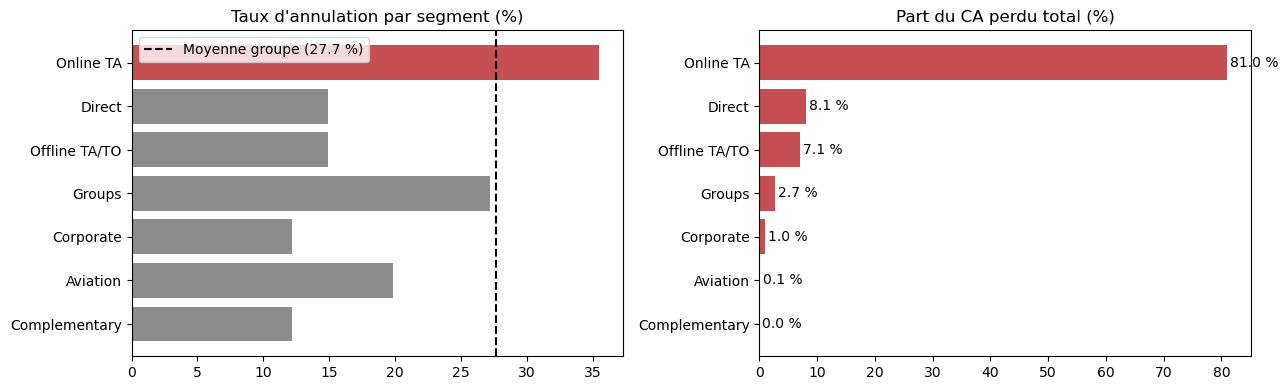

In [11]:
taux_moyen = sql("SELECT 100.0 * AVG(est_annule) AS t FROM reservations")["t"][0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

couleurs = ["#C44E52" if v == "Au-dessus" else "#8C8C8C" for v in q2["vs_moyenne_groupe"]]
axes[0].barh(q2["segment_marche"], q2["taux_annulation_pct"], color=couleurs)
axes[0].axvline(taux_moyen, color="black", linestyle="--", label=f"Moyenne groupe ({taux_moyen:.1f} %)")
axes[0].invert_yaxis()
axes[0].set_title("Taux d'annulation par segment (%)")
axes[0].legend()

axes[1].barh(q2["segment_marche"], q2["part_du_ca_perdu_pct"], color="#C44E52")
axes[1].invert_yaxis()
axes[1].set_title("Part du CA perdu total (%)")
for i, v in enumerate(q2["part_du_ca_perdu_pct"]):
    axes[1].text(v + 0.5, i, f"{v} %", va="center")

plt.tight_layout()
plt.show()

##### **Interprétation** :
##### - **Online TA** (agences en ligne) est le **seul segment au-dessus de la moyenne** (35,5 % contre 27,7 %). C'est aussi le premier segment en volume (51 285 réservations) et en CA réalisé (13,0 M€).
##### - Online TA concentre **81 % du CA perdu** (9,3 M€) : c'est à la fois le segment qui rapporte le plus et celui qui coûte le plus en annulations.
##### - Les segments **Direct** et **Offline TA/TO** annulent deux fois moins (14,9 %) ; **Corporate** encore moins (12,2 %).
##### - **Groups** (27,2 %) est juste sous la moyenne et ne pèse que 2,7 % du CA perdu, une fois les doublons et les blocs « Non Refund » remis à leur juste place.
##### - ***Pour la direction*** : l'effort de réduction des annulations doit porter d'abord sur **Online TA** (conditions d'annulation, acomptes, relances). Développer le **canal direct**, moins risqué, réduit la dépendance aux agences en ligne.

---
## **4. Requête 3 — Évolution mensuelle du taux d'annulation par hôtel**
##### **Question** : comment le taux d'annulation évolue-t-il mois par mois pour chaque hôtel, et comment se compare-t-il au mois précédent ?
##### **Techniques** :
##### - une **CTE** (`WITH mensuel AS (...)`) calcule d'abord le taux par hôtel et par mois ;
##### - la **fonction de fenêtrage** `LAG()` récupère le taux du mois précédent **du même hôtel** (`PARTITION BY hotel`), dans l'ordre chronologique (`ORDER BY annee, mois`), pour calculer l'écart en points.

In [12]:
requete_q3 = """
WITH mensuel AS (
    SELECT hotel,
           annee_arrivee                      AS annee,
           num_mois                           AS mois,
           COUNT(*)                           AS nb_reservations,
           ROUND(100.0 * AVG(est_annule), 1)  AS taux_annulation_pct
    FROM reservations
    GROUP BY hotel, annee_arrivee, num_mois
)
SELECT hotel,
       annee,
       mois,
       nb_reservations,
       taux_annulation_pct,
       LAG(taux_annulation_pct) OVER (PARTITION BY hotel ORDER BY annee, mois)  AS taux_mois_precedent,
       ROUND(taux_annulation_pct
             - LAG(taux_annulation_pct) OVER (PARTITION BY hotel ORDER BY annee, mois), 1) AS ecart_points
FROM mensuel
ORDER BY hotel, annee, mois;
"""
q3 = sql(requete_q3)
q3.head(15)

,hotel,annee,mois,nb_reservations,taux_annulation_pct,taux_mois_precedent,ecart_points
0,City Hotel,2015,7,390,59.5,NaN,NaN
1,City Hotel,2015,8,1098,20.9,59.5,-38.6
2,City Hotel,2015,9,1659,18.9,20.9,-2.0
3,City Hotel,2015,10,1541,18.8,18.9,-0.1
4,City Hotel,2015,11,787,17.4,18.8,-1.4
5,City Hotel,2015,12,1005,21.9,17.4,4.5
6,City Hotel,2016,1,1021,20.8,21.9,-1.1
7,City Hotel,2016,2,1638,22.6,20.8,1.8
8,City Hotel,2016,3,2351,27.4,22.6,4.8
9,City Hotel,2016,4,2402,31.1,27.4,3.7


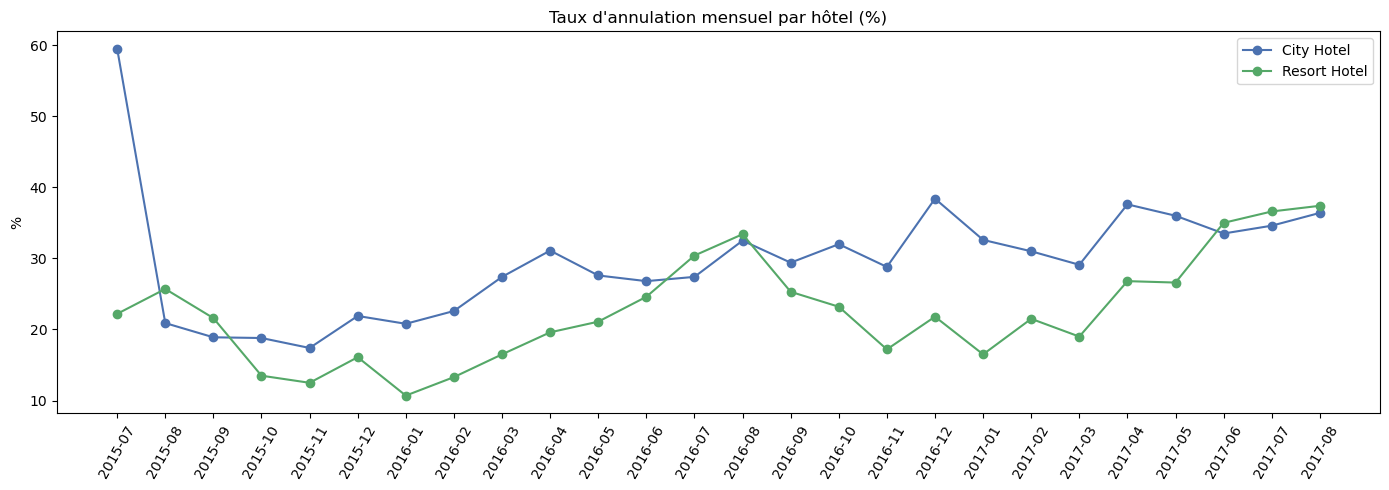

In [13]:
q3["periode"] = q3["annee"].astype(str) + "-" + q3["mois"].astype(str).str.zfill(2)

fig, ax = plt.subplots(figsize=(14, 5))
for hotel, couleur in [("City Hotel", "#4C72B0"), ("Resort Hotel", "#55A868")]:
    d = q3[q3["hotel"] == hotel]
    ax.plot(d["periode"], d["taux_annulation_pct"], marker="o", label=hotel, color=couleur)
ax.set_title("Taux d'annulation mensuel par hôtel (%)")
ax.set_ylabel("%")
ax.legend()
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

##### **Les plus fortes hausses d'un mois sur l'autre** (en excluant juillet 2015, premier mois sans mois précédent) :

In [14]:
q3.dropna(subset=["ecart_points"]).sort_values("ecart_points", ascending=False).head(6)

,hotel,annee,mois,nb_reservations,taux_annulation_pct,taux_mois_precedent,ecart_points,periode
17,City Hotel,2016,12,1978,38.4,28.8,9.6,2016-12
21,City Hotel,2017,4,2660,37.6,29.1,8.5,2017-04
49,Resort Hotel,2017,6,1524,35.0,26.6,8.4,2017-06
47,Resort Hotel,2017,4,1469,26.8,19.0,7.8,2017-04
38,Resort Hotel,2016,7,1352,30.4,24.6,5.8,2016-07
13,City Hotel,2016,8,2800,32.5,27.4,5.1,2016-08


##### **Interprétation** :
##### - **Tendance à la hausse** pour les deux hôtels : le City passe d'environ 19-22 % fin 2015 à **34-38 %** en 2017 ; le Resort d'environ 11-16 % l'hiver 2015-2016 à **35-37 %** à l'été 2017.
##### - **Saisonnalité marquée au Resort** : creux en hiver (10,7 % en janvier 2016), pics en été (33,4 % en août 2016, 37,4 % en août 2017). L'été, le **Resort rattrape et dépasse le City**.
##### - Le City est plus **stable** sur l'année, mais à un niveau élevé, avec des hausses ponctuelles (+9,6 points en décembre 2016, +8,5 points en avril 2017).
##### - ***Point d'attention*** : **juillet 2015 au City** (59,5 % sur 390 réservations) est une **anomalie** de démarrage : premier mois des données, petit volume et forte part de réservations de groupe (37 %). À ne pas interpréter comme une tendance.
##### - ***Pour la direction*** : renforcer les actions préventives **avant la haute saison** (printemps-été), en particulier au Resort, et suivre ce tableau chaque mois comme indicateur d'alerte.

---
## **5. Requête 4 — Top 10 des agents par CA et leur taux d'annulation**
##### **Question** : quels sont les 10 agents qui génèrent le plus de CA réalisé, quelle part du CA total représentent-ils, et quel est leur taux d'annulation ?
##### **Techniques** :
##### - une **CTE** agrège par agent (`WHERE id_agent IS NOT NULL` exclut les réservations sans agent) ;
##### - **`RANK() OVER (ORDER BY ...)`** classe les agents par CA ;
##### - **`SUM() OVER (ORDER BY ...)`** calcule la **part cumulée** du CA ;
##### - une **sous-requête** donne le CA réalisé total du groupe (avec et sans agent) pour calculer les parts.

In [15]:
requete_q4 = """
WITH agents AS (
    SELECT CAST(id_agent AS INTEGER)                                        AS agent,
           COUNT(*)                                                         AS nb_reservations,
           ROUND(100.0 * AVG(est_annule), 1)                                AS taux_annulation_pct,
           SUM(CASE WHEN est_annule = 0 THEN total_revenue ELSE 0 END)      AS ca_realise
    FROM reservations
    WHERE id_agent IS NOT NULL
    GROUP BY CAST(id_agent AS INTEGER)
)
SELECT RANK() OVER (ORDER BY ca_realise DESC)                               AS rang,
       agent,
       nb_reservations,
       taux_annulation_pct,
       ROUND(ca_realise / 1e6, 2)                                           AS ca_realise_meur,
       ROUND(100.0 * ca_realise
             / (SELECT SUM(total_revenue) FROM reservations WHERE est_annule = 0), 1) AS part_ca_total_pct,
       ROUND(100.0 * SUM(ca_realise) OVER (ORDER BY ca_realise DESC)
             / (SELECT SUM(total_revenue) FROM reservations WHERE est_annule = 0), 1) AS part_cumulee_pct
FROM agents
ORDER BY rang
LIMIT 10;
"""
q4 = sql(requete_q4)
q4

,rang,agent,nb_reservations,taux_annulation_pct,ca_realise_meur,part_ca_total_pct,part_cumulee_pct
0,1,9,28654,40.2,6.50,28.3,28.3
1,2,240,12907,38.3,3.50,15.2,43.5
2,3,250,2766,17.8,1.38,6.0,49.5
3,4,14,3329,17.5,1.09,4.7,54.3
4,5,7,3282,13.3,0.92,4.0,58.3
5,6,40,982,7.8,0.63,2.8,61.0
6,7,241,1628,13.3,0.63,2.7,63.8
7,8,8,1371,28.1,0.39,1.7,65.5
8,9,28,1476,5.9,0.38,1.7,67.1
9,10,314,832,15.3,0.31,1.4,68.5


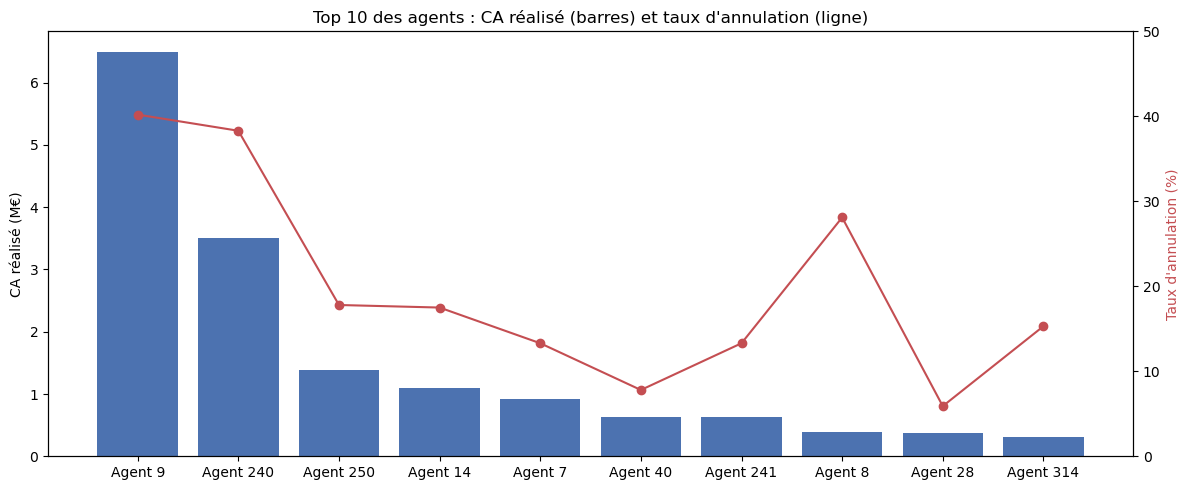

In [16]:
fig, ax1 = plt.subplots(figsize=(12, 5))
etiquettes = "Agent " + q4["agent"].astype(str)

ax1.bar(etiquettes, q4["ca_realise_meur"], color="#4C72B0")
ax1.set_ylabel("CA réalisé (M€)")
ax1.set_title("Top 10 des agents : CA réalisé (barres) et taux d'annulation (ligne)")

ax2 = ax1.twinx()
ax2.plot(etiquettes, q4["taux_annulation_pct"], color="#C44E52", marker="o")
ax2.set_ylabel("Taux d'annulation (%)", color="#C44E52")
ax2.set_ylim(0, 50)

plt.tight_layout()
plt.show()

##### **Interprétation** :
##### - **Forte dépendance** : les agents **9** et **240** génèrent à eux deux **43,5 % du CA réalisé** du groupe (6,5 M€ et 3,5 M€). Les 10 premiers agents en représentent **68,5 %**.
##### - Ce sont aussi les agents qui **annulent le plus** parmi les gros contributeurs : **40,2 %** pour l'agent 9 et **38,3 %** pour l'agent 240, contre 6 % à 18 % pour les agents classés 3 à 10.
##### - Les agents 250, 14 et 7 apportent chacun 0,9 à 1,4 M€ avec un risque bien plus faible (13 % à 18 %).
##### - ***Pour la direction*** : **renégocier les conditions** avec les agents 9 et 240 (acompte, délai d'annulation, pénalités) est le levier le plus direct sur le CA perdu. À moyen terme, **diversifier** vers des agents moins risqués réduit la dépendance.

---
## **6. Requête 5 : Taux d'annulation par tranche de délai de réservation**
##### **Question** : comment le taux d'annulation et le CA perdu varient-ils selon le délai entre la réservation et l'arrivée ?
##### **Techniques** : `CASE WHEN` dans une **CTE** pour créer les tranches de délai, puis `GROUP BY`, agrégats et sous-requête pour la part du CA perdu. Les tranches sont numérotées (`1.`, `2.`...) pour être triées dans l'ordre.

In [18]:
requete_q5 = """
WITH tranches AS (
    SELECT est_annule,
           total_revenue,
           CASE
               WHEN delai_reservation_jours <= 7   THEN '1. 0-7 jours'
               WHEN delai_reservation_jours <= 30  THEN '2. 8-30 jours'
               WHEN delai_reservation_jours <= 90  THEN '3. 31-90 jours'
               WHEN delai_reservation_jours <= 180 THEN '4. 91-180 jours'
               ELSE '5. Plus de 180 jours'
           END AS tranche_delai
    FROM reservations
)
SELECT tranche_delai,
       COUNT(*)                                                             AS nb_reservations,
       ROUND(100.0 * AVG(est_annule), 1)                                    AS taux_annulation_pct,
       ROUND(SUM(CASE WHEN est_annule = 1 THEN total_revenue ELSE 0 END) / 1e6, 2) AS ca_perdu_meur,
       ROUND(100.0 * SUM(CASE WHEN est_annule = 1 THEN total_revenue ELSE 0 END)
             / (SELECT SUM(total_revenue) FROM reservations WHERE est_annule = 1), 1) AS part_du_ca_perdu_pct
FROM tranches
GROUP BY tranche_delai
ORDER BY tranche_delai;
"""
q5 = sql(requete_q5)
q5

,tranche_delai,nb_reservations,taux_annulation_pct,ca_perdu_meur,part_du_ca_perdu_pct
0,1. 0-7 jours,17855,8.5,0.39,3.4
1,2. 8-30 jours,16234,25.5,1.77,15.4
2,3. 31-90 jours,22633,32.1,3.31,28.8
3,4. 91-180 jours,18190,35.1,3.46,30.2
4,5. Plus de 180 jours,11725,39.8,2.56,22.3


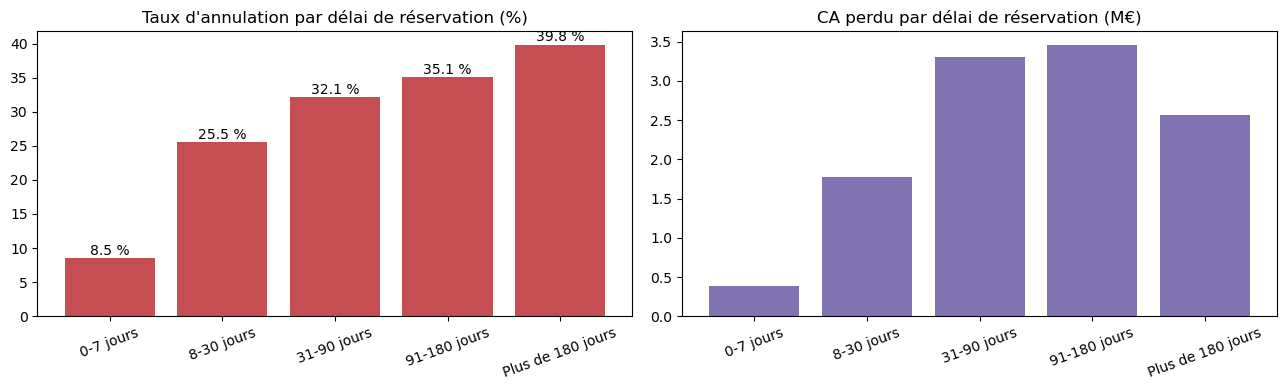

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
etiquettes = q5["tranche_delai"].str[3:]

axes[0].bar(etiquettes, q5["taux_annulation_pct"], color="#C44E52")
axes[0].set_title("Taux d'annulation par délai de réservation (%)")
for i, v in enumerate(q5["taux_annulation_pct"]):
    axes[0].text(i, v + 0.5, f"{v} %", ha="center")

axes[1].bar(etiquettes, q5["ca_perdu_meur"], color="#8172B2")
axes[1].set_title("CA perdu par délai de réservation (M€)")

for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

##### **Interprétation** :
##### - Le risque **augmente régulièrement avec le délai** : **8,5 %** pour une réservation à moins d'une semaine, **25,5 %** entre 8 et 30 jours, jusqu'à **39,8 %** au-delà de 180 jours. Plus le client réserve tôt, plus il a le temps de changer d'avis ou de trouver une meilleure offre.
##### - En CA, les réservations à **31-180 jours** pèsent le plus : **59 % du CA perdu** (6,8 M€). Elles combinent un taux élevé et un volume important.
##### - Les réservations de dernière minute (0-7 jours) ne représentent que 3,4 % du CA perdu.
##### - ***Pour la direction*** : demander un **acompte** ou une **confirmation** pour les réservations faites **plus d'un mois à l'avance**, et relancer le client à l'approche de la date d'arrivée. Le délai est aussi une variable clé du modèle de prédiction.

---
## **7. Requête 6 : Profils les plus exposés : segment × type de client**
##### **Question** : quelles combinaisons segment de marché × type de client présentent les taux d'annulation les plus élevés, et quel CA perdu représentent-elles ?
##### **Techniques** : `GROUP BY` sur **deux colonnes**, `HAVING COUNT(*) >= 500` pour ne garder que les profils fiables (effectif suffisant), `ORDER BY` et `LIMIT`.

In [20]:
requete_q6 = """
SELECT segment_marche,
       type_client,
       COUNT(*)                                                             AS nb_reservations,
       ROUND(100.0 * AVG(est_annule), 1)                                    AS taux_annulation_pct,
       ROUND(SUM(CASE WHEN est_annule = 1 THEN total_revenue ELSE 0 END) / 1e6, 2) AS ca_perdu_meur
FROM reservations
GROUP BY segment_marche, type_client
HAVING COUNT(*) >= 500
ORDER BY taux_annulation_pct DESC
LIMIT 10;
"""
q6 = sql(requete_q6)
q6

,segment_marche,type_client,nb_reservations,taux_annulation_pct,ca_perdu_meur
0,Groups,Transient,913,65.2,0.14
1,Online TA,Transient,47050,37.4,9.04
2,Online TA,Contract,1318,23.7,0.12
3,Groups,Transient-Party,3902,17.9,0.17
4,Offline TA/TO,Transient-Party,3057,16.5,0.14
5,Offline TA/TO,Transient,8798,15.6,0.55
6,Direct,Transient,10664,15.2,0.88
7,Corporate,Transient-Party,1019,14.3,0.03
8,Complementary,Transient,645,12.4,0.00
9,Online TA,Transient-Party,2748,11.9,0.13


##### **Interprétation** :
##### - **Online TA × Transient** (clients individuels via agence en ligne) est le **profil clé** : 47 050 réservations, **37,4 %** d'annulation et **9,0 M€ de CA perdu**, soit près de **80 %** du CA perdu du groupe à lui seul.
##### - **Groups × Transient** a le taux le plus élevé (**65,2 %**) mais sur seulement 913 réservations et 0,14 M€ : ce taux est tiré par des réservations en bloc « Non Refund » (60 % du profil, toutes annulées). Profil à surveiller, mais peu d'enjeu financier.
##### - Les profils liés à un cadre (**Transient-Party**, **Contract**) ou passés en **Direct** et **Corporate** restent entre 12 % et 18 %.
##### - ***Pour la direction*** : le taux seul ne suffit pas, il faut le croiser avec le **CA en jeu**. C'est exactement le principe de la **règle de priorisation** du modèle : cibler les réservations dont la **perte attendue** (probabilité d'annulation × CA) est la plus forte.

---
## **8. Synthèse pour la direction**

| # | Question | Résultat clé | Recommandation |
|---|---|---|---|
| 1 | Hôtels | City 30,2 % vs Resort 23,7 % ; ~11,5 M€ de CA perdu (1/3 du CA potentiel) | Priorité City, sans négliger le Resort |
| 2 | Segments | Online TA seul au-dessus de la moyenne (35,5 %), 81 % du CA perdu | Conditions d'annulation et acomptes ciblés ; développer le direct |
| 3 | Saisonnalité | Hausse continue 2015-2017 ; pics d'été au Resort | Actions préventives avant la haute saison |
| 4 | Agents | Agents 9 et 240 : 43,5 % du CA, ~40 % d'annulation | Renégocier les conditions, diversifier |
| 5 | Délai | De 8,5 % (0-7 j) à 39,8 % (> 180 j) | Acompte / confirmation au-delà de 30 jours |
| 6 | Profils | Online TA × Transient : 37,4 %, 9,0 M€ perdus | Cibler par perte attendue (probabilité × CA) |

##### ***Limites*** : le CA est **estimé** (prix moyen × nuits, hors extras) ; les données couvrent **juillet 2015 à août 2017** pour deux hôtels portugais ; la suppression des doublons fait baisser certains taux (notamment Groups) par rapport aux données brutes.
##### Ces constats rejoignent ceux de l'analyse exploratoire en Python et justifient les variables utilisées dans le **modèle de classification**.

In [21]:
# Export des requêtes dans un fichier .sql (livrable du dépôt GitHub)
requetes = {
    "Contrôle": requete_verif,
    "Requête 1 - Vue d'ensemble par hôtel": requete_q1,
    "Requête 2 - Segments de marché": requete_q2,
    "Requête 3 - Évolution mensuelle (CTE + LAG)": requete_q3,
    "Requête 4 - Top 10 des agents (RANK, SUM OVER)": requete_q4,
    "Requête 5 - Délai de réservation (CTE + CASE)": requete_q5,
    "Requête 6 - Profils segment x type de client": requete_q6,
}
with open("requetes_hotel_booking.sql", "w", encoding="utf-8") as f:
    for titre, r in requetes.items():
        f.write(f"-- {titre}\n{r.strip()}\n\n")
print("Fichier requetes_hotel_booking.sql créé.")

conn.close()

Fichier requetes_hotel_booking.sql créé.
